In [1]:
import numpy as np
import mrcfile
from pathlib import Path
from matplotlib import pyplot as plt   
import torch
import pymeshlab
from scipy.spatial import cKDTree
import einops

In [2]:
tomogram_base = Path("/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/20240111_WaffleHipp_116/best_alignment/")
tomo_name = "20240111_WaffleHipp_116"

In [3]:
with mrcfile.open(list(tomogram_base.glob(f"*_flat.mrc"))[0]) as mrc:
    tomogram_data = torch.tensor(mrc.data.copy())

In [4]:
prems = pymeshlab.MeshSet()
prems.load_new_mesh(str(tomogram_base / "aunps" / f"presynatpticmembranes.glb"))
postms = pymeshlab.MeshSet()
postms.load_new_mesh(str(tomogram_base / "aunps" / f"postsynapticmembranes.glb"))



prem = prems.current_mesh()
postm = postms.current_mesh()

# Magic conversion to nm and correct coordinate system
pre_points = prem.vertex_matrix().copy()[:,[0,2,1]][::10] * np.array([10,-10,10])
print(pre_points.shape)
post_points = postm.vertex_matrix().copy()[:,[0,2,1]][::10] * np.array([10,-10,10])
print(post_points.shape)

pre_normals = prem.vertex_normal_matrix().copy()[:,[0,2,1]][::10] * np.array([10,-10,10])
post_normals = postm.vertex_normal_matrix().copy()[:,[0,2,1]][::10] * np.array([10,-10,10])


(99245, 3)
(47841, 3)


In [5]:
pre_tree = cKDTree(pre_points)
post_tree = cKDTree(post_points)
active_zone = pre_tree.query_ball_tree(post_tree, 28)
pre_points_in_active_zone = []
post_poins_in_active_zone = []
for i,a in enumerate(active_zone):
        if len(a) > 0:
            for psp in a:
                 diff = pre_points[i] - post_points[psp]
                 if np.dot(pre_normals[i], diff) < 0 and np.dot(post_normals[psp], diff) > 0:
                       pre_points_in_active_zone.append(i)
                       post_poins_in_active_zone.append(psp)
                       
            #pre_points_in_active_zone.append(pre_points[i])
    #np.int(np.concatenate(active_zone))
post_poins_in_active_zone = post_points[np.unique(np.array(post_poins_in_active_zone).astype(int))]
pre_points_in_active_zone = pre_points[np.unique(np.array(pre_points_in_active_zone).astype(int))] 


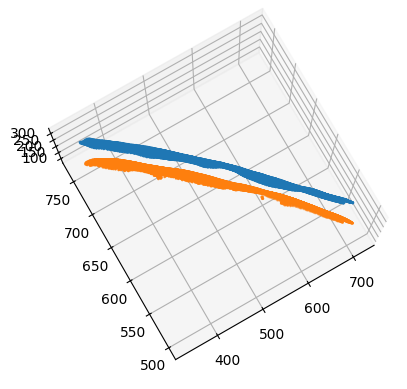

In [6]:
plt.figure()
ax = plt.subplot(111, projection='3d')
# rotate plot
ax.view_init(elev=80, azim=240)
ax.scatter(post_poins_in_active_zone[:,0], post_poins_in_active_zone[:,1], post_poins_in_active_zone[:,2], s=1)
ax.scatter(pre_points_in_active_zone[:,0], pre_points_in_active_zone[:,1], pre_points_in_active_zone[:,2], s=1)


In [7]:
from findingampa.utils.analysis import create_coordinate_system_from_points

cs, center = create_coordinate_system_from_points(pre_points_in_active_zone, post_poins_in_active_zone)

center

array([554.86496198, 634.66954834, 209.3448272 ])

In [8]:
all_poins = np.concatenate([pre_points_in_active_zone, post_poins_in_active_zone])
all_poins_transformed = (torch.tensor(all_poins) - torch.tensor(center)) @ torch.tensor(cs.T)
w, h, d = (torch.max(-torch.min(all_poins_transformed, dim=0).values, torch.max(all_poins_transformed, dim=0).values).floor() + 1).int()
w

tensor(158, dtype=torch.int32)

In [9]:
x = torch.linspace(-w, w, 2*w+1, dtype=torch.float64)
y = torch.linspace(-h, h, 2*h+1, dtype=torch.float64)
z = torch.linspace(-d, d, 2*d+1, dtype=torch.float64)
mg = torch.cartesian_prod(x, y, z)
#print(mg)
# Construct 100x 100 mesh around pre points center in fractional coordinates using v2 and v3
grid = mg @ torch.tensor([cs]) + torch.tensor(center)


/tmp/ipykernel_1282178/3778119087.py:7: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:278.)
  grid = mg @ torch.tensor([cs]) + torch.tensor(center)


In [20]:
pre_dis, pre_i = pre_tree.query(grid, k=1)
post_dis, post_i = post_tree.query(grid, k=1)

grid_selection = np.logical_and(pre_dis < 20, post_dis < 20)
np.sum(grid_selection)
grid_selection.shape


(1, 7679325)

In [21]:
grid.shape

torch.Size([1, 7679325, 3])

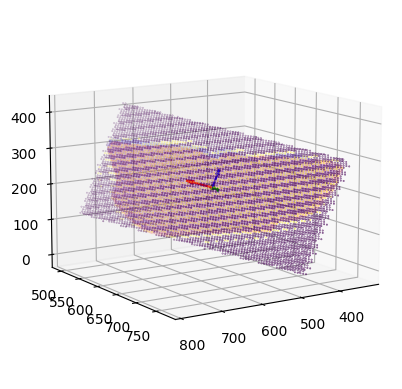

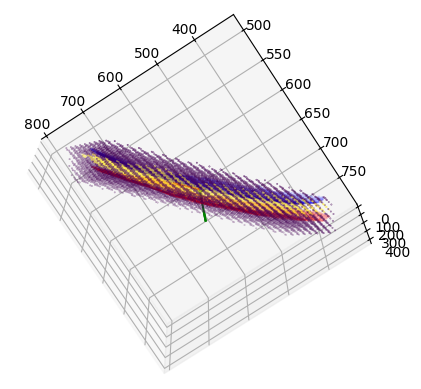

In [23]:
# Calculate elev, azim, roll to look down cs[2] axis
elev = np.arcsin(cs[2][2]) * 180 / np.pi
azim= np.arctan2(cs[2][1], cs[2][0]) * 180 / np.pi
roll=0

plt.figure()
ax = plt.subplot(111, projection='3d')
# rotate plot
ax.view_init(elev=elev, azim=azim,roll=roll)
ax.scatter(post_poins_in_active_zone[:,0], post_poins_in_active_zone[:,1], post_poins_in_active_zone[:,2], c='r',s=0.1,alpha=0.1)
ax.scatter(pre_points_in_active_zone[:,0], pre_points_in_active_zone[:,1], pre_points_in_active_zone[:,2], c='b', s=0.1,alpha=0.1)

ax.scatter(center[0], center[1], center[2], c='g', s=10)
ax.quiver(center[0], center[1], center[2], cs[2][0]*50, cs[2][1]*50, cs[2][2]*50, color='g')
ax.quiver(center[0], center[1], center[2], cs[0][0]*50, cs[0][1]*50, cs[0][2]*50, color='b')
ax.quiver(center[0], center[1], center[2], cs[1][0]*50, cs[1][1]*50, cs[1][2]*50, color='r')
ax.scatter(grid.reshape(-1,3)[::1000,0], grid.reshape(-1,3)[::1000,1], grid.reshape(-1,3)[::1000,2], c=grid_selection[0,::1000], s=0.1)
plt.show()
# Calculate elev, azim, roll to look down cs[2] axis
elev += 90

plt.figure()
ax = plt.subplot(111, projection='3d')
# rotate plot
ax.view_init(elev=elev, azim=azim,roll=roll)
ax.scatter(post_poins_in_active_zone[:,0], post_poins_in_active_zone[:,1], post_poins_in_active_zone[:,2], c='r',s=0.1,alpha=0.1)
ax.scatter(pre_points_in_active_zone[:,0], pre_points_in_active_zone[:,1], pre_points_in_active_zone[:,2], c='b', s=0.1,alpha=0.1)

ax.scatter(center[0], center[1], center[2], c='g', s=10)
ax.quiver(center[0], center[1], center[2], cs[2][0]*50, cs[2][1]*50, cs[2][2]*50, color='g')
ax.quiver(center[0], center[1], center[2], cs[0][0]*50, cs[0][1]*50, cs[0][2]*50, color='b')
ax.quiver(center[0], center[1], center[2], cs[1][0]*50, cs[1][1]*50, cs[1][2]*50, color='r')
ax.scatter(grid.reshape(-1,3)[::1000,0], grid.reshape(-1,3)[::1000,1], grid.reshape(-1,3)[::1000,2], c=grid_selection[0,::1000], s=0.1)
plt.show()

In [12]:
# Convert grid to coordinates within {-1 and 1} as required by pytorch
torch.tensor(tomogram_data.shape).flip(dims=(0,)).double()

grid_sc = grid / (torch.tensor(tomogram_data.shape).flip(dims=(0,)).double() / 2.0 ) - 1.0

grid_sc.shape

grid_sc = grid_sc.reshape(1,2*w+1,2*h+1,2*d+1,3).float()
tomogram_data_sc = tomogram_data.reshape(1,1, *tomogram_data.shape)

In [26]:
res = torch.nn.functional.grid_sample(tomogram_data_sc, grid_sc)
res = res [0,0]
rshape = res.shape
res = res.flatten() * grid_selection
res = res.reshape(rshape)

/home/gouauxlab/andecath/env/lib/python3.11/site-packages/torch/nn/functional.py:4902: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  warnings.warn(


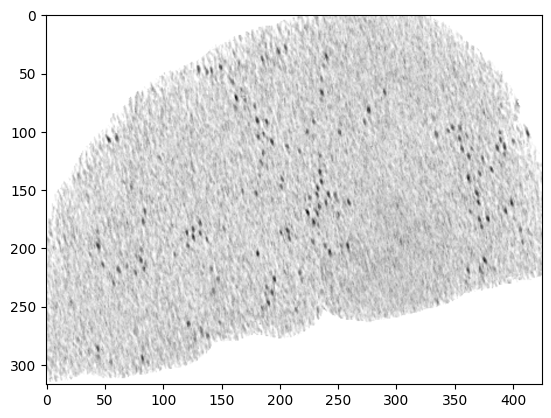

In [28]:
plt.imshow(torch.min(res,axis=2).values,cmap='gray',interpolation='mitchell')

In [29]:
with mrcfile.open(list(tomogram_base.glob(f"*_ddw.mrc"))[0]) as mrc:
    tomogram_data_ddw = torch.tensor(mrc.data.copy())


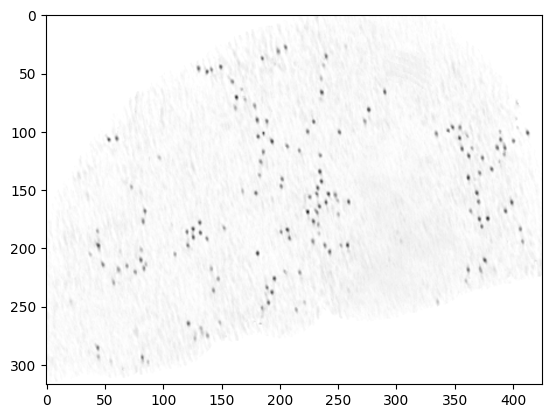

In [31]:
tomogram_data_ddw_sc = tomogram_data_ddw.reshape(1,1, *tomogram_data.shape)
res_ddw = torch.nn.functional.grid_sample(tomogram_data_ddw_sc, grid_sc)
res_ddw = res_ddw [0,0]
res_ddw = res_ddw.flatten() * grid_selection
res_ddw = res_ddw.reshape(rshape)
tomogram_data_den_sc = tomogram_data_den.reshape(1,1, *tomogram_data.shape)
plt.imshow(torch.min(res_ddw,axis=2).values,cmap='gray',interpolation='mitchell')
plt.show()


In [32]:
from scipy.spatial import cKDTree
import starfile
aunp_star = tomogram_base / "aunps" /  "aunp_tm.star"


aunp_data = starfile.read(aunp_star)

pre_kd = cKDTree(pre_points_in_active_zone)
post_kd = cKDTree(post_poins_in_active_zone)

aunp_pos = aunp_data[["faTM_PeakX", "faTM_PeakY", "faTM_PeakZ"]].values
aunp_data["Size"] = aunp_data["faTomo_gaussianFitSigmaX"] * aunp_data["faTomo_gaussianFitSigmaY"] * aunp_data["faTomo_gaussianFitSigmaZ"]
pre_dists, pre_idxs = pre_kd.query(aunp_pos)
post_dists, post_idxs = post_kd.query(aunp_pos)
aunp_data["pre_dist"] = pre_dists
aunp_data["post_dist"] = post_dists



In [33]:
aunp_data

,faTM_PeakX,faTM_PeakY,faTM_PeakZ,faTM_PeakScore,faTM_gaussianFitX,faTM_gaussianFitY,faTM_gaussianFitZ,faTM_gaussianFitSigmaX,faTM_gaussianFitSigmaY,faTM_gaussianFitSigmaZ,...,faTomo_gaussianFitX,faTomo_gaussianFitY,faTomo_gaussianFitZ,faTomo_gaussianFitSigmaX,faTomo_gaussianFitSigmaY,faTomo_gaussianFitSigmaZ,faTomo_gaussianFitAmplitude,Size,pre_dist,post_dist
0,334.0,714.0,45.0,0.729985,0.187268,0.124383,-0.257015,0.691510,0.955611,2.636283,...,-0.313304,-0.625987,-0.588474,0.776348,1.124767,2.608216,-7.243967,2.277522,130.817254,145.314585
1,443.0,414.0,74.0,0.705601,-0.124338,0.145076,-0.342096,0.810147,0.853849,2.744272,...,-0.579472,-0.457477,-0.256670,0.895914,0.998276,3.127828,-6.950182,2.797434,255.514237,281.035252
2,873.0,515.0,161.0,0.685687,-0.001337,-0.161039,-0.238949,0.739113,0.861779,2.747041,...,-0.473948,-0.756761,-0.723724,0.763188,1.064830,2.762153,-6.651752,2.244706,174.932298,157.489024
3,411.0,870.0,28.0,0.681353,-0.300015,0.057409,-0.018626,0.710494,0.950784,3.062466,...,-0.704300,-0.572988,-0.255462,0.764680,1.143103,3.127033,-6.376008,2.733365,191.879961,177.885062
4,558.0,644.0,139.0,0.674704,0.143490,0.071686,-0.026987,0.741645,0.965365,2.729201,...,-0.321243,-0.502237,-0.169431,0.729219,1.217905,2.946894,-6.181626,2.617194,5.805471,20.409295
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15914,613.0,603.0,124.0,0.300002,0.291094,-0.456648,0.019534,0.761813,0.778882,2.838962,...,-0.310210,-1.531911,-0.388890,0.985116,1.262769,2.921788,-1.942412,3.634628,1.820541,23.692987
15915,631.0,569.0,36.0,0.300002,-0.038309,0.254834,0.147208,0.695586,1.373639,2.876650,...,-0.526245,-0.187812,-0.636459,0.407983,1.214381,2.607503,-3.569879,1.291879,47.053580,64.028914
15916,269.0,518.0,152.0,0.300002,0.329179,0.039163,-0.500646,0.552327,1.041598,2.583408,...,-0.335516,-0.261015,-0.919606,0.645757,1.358755,2.484069,-2.152178,2.179586,242.075975,268.745322
15917,237.0,727.0,227.0,0.300001,-0.181484,-0.342500,1.389931,0.826020,1.338928,3.019393,...,-0.641084,-0.942639,1.637923,0.800346,1.533690,3.009761,-2.422493,3.694429,107.047561,123.260429


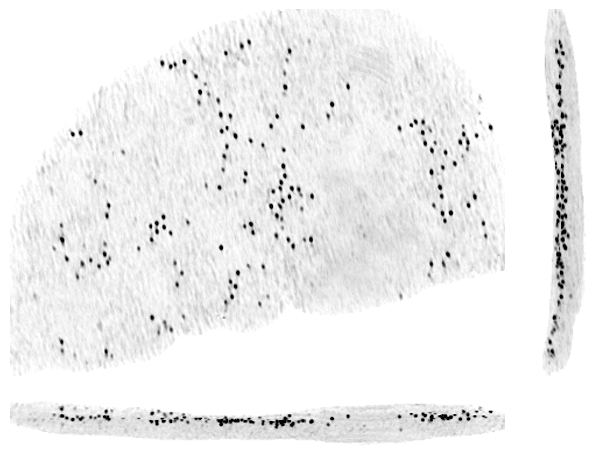

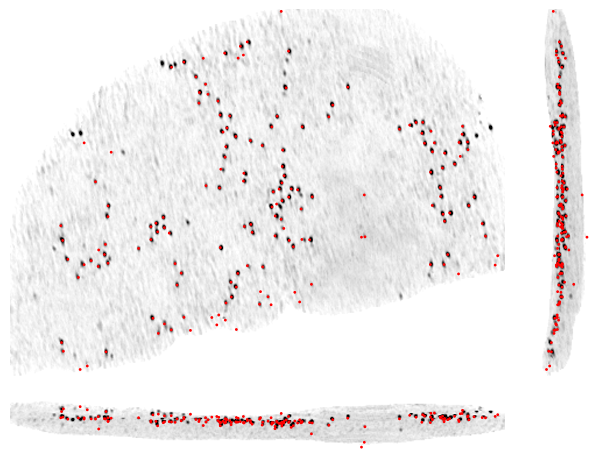

In [69]:
from matplotlib import gridspec
in_cleft_aunps = aunp_data[(aunp_data["pre_dist"] < 25) & (aunp_data["post_dist"] < 25)]

slected_aunps = in_cleft_aunps[in_cleft_aunps["faTM_PeakScore"] > 0.35]
slected_aunps = slected_aunps[slected_aunps["faTomo_gaussianFitAmplitude"] < -4]
selected_aunp_pos = slected_aunps[["faTM_PeakX", "faTM_PeakY", "faTM_PeakZ"]].values - slected_aunps[["faTomo_gaussianFitZ", "faTomo_gaussianFitY", "faTomo_gaussianFitX"]].values
selected_aunp_pos_transformed = (torch.tensor(selected_aunp_pos) - torch.tensor(center)) @ torch.tensor(cs.T)
# Generagte figure for panels of different projections
fig = plt.figure()
gs = gridspec.GridSpec(2, 2, width_ratios=[res_ddw.shape[1], res_ddw.shape[2]], height_ratios=[res_ddw.shape[0], res_ddw.shape[2]])

axxy = plt.subplot(gs[0, 0])
axxz = plt.subplot(gs[0, 1], sharey=axxy)
axyz = plt.subplot(gs[1, 0], sharex=axxy)

axxy.imshow(torch.min(res_ddw,axis=2).values,cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-1.5)
axxz.imshow(torch.min(res_ddw,axis=1).values,cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-1.5)
axyz.imshow(torch.min(res_ddw,axis=0).values.T,cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-1.5)
# Hide axes 
axxy.axis('off')
axxz.axis('off')
axyz.axis('off')
plt.tight_layout()
plt.show()
fig = plt.figure()
gs = gridspec.GridSpec(2, 2, width_ratios=[res_ddw.shape[1], res_ddw.shape[2]], height_ratios=[res_ddw.shape[0], res_ddw.shape[2]])

axxy = plt.subplot(gs[0, 0])
axxz = plt.subplot(gs[0, 1], sharey=axxy)
axyz = plt.subplot(gs[1, 0], sharex=axxy)

axxy.imshow(torch.min(res_ddw,axis=2).values,cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-1.5)
axxz.imshow(torch.min(res_ddw,axis=1).values,cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-1.5)
axyz.imshow(torch.min(res_ddw,axis=0).values.T,cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-1.5)
# Hide axes 
axxy.axis('off')
axxz.axis('off')
axyz.axis('off')
plt.tight_layout()
axxy.scatter(selected_aunp_pos_transformed[:,1]+h, selected_aunp_pos_transformed[:,0]+w, s=1,facecolors='none', edgecolors='r')
axxz.scatter(selected_aunp_pos_transformed[:,2]+d, selected_aunp_pos_transformed[:,0]+w, s=1,facecolors='none', edgecolors='r')
axyz.scatter(selected_aunp_pos_transformed[:,1]+h, selected_aunp_pos_transformed[:,2]+d, s=1,facecolors='none', edgecolors='r')

plt.show()

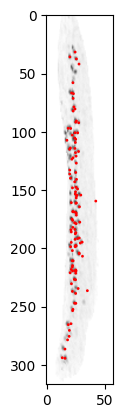

In [42]:
plt.imshow(torch.min(res_ddw,axis=1).values,cmap='gray',interpolation='mitchell')
plt.scatter(selected_aunp_pos_transformed[:,2]+d, selected_aunp_pos_transformed[:,0]+w, s=1,facecolors='none', edgecolors='r')
plt.show()

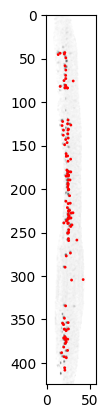

In [43]:
plt.imshow(torch.min(res_ddw,axis=0).values,cmap='gray',interpolation='mitchell')
plt.scatter(selected_aunp_pos_transformed[:,2]+d, selected_aunp_pos_transformed[:,1]+h, s=1,facecolors='none', edgecolors='r')
plt.show()